# 🏔️ Landslide Detection with a Fine-tuned Geospatial Foundation Model

## Part 2 — Inference & Evaluation with Prithvi-EO-2.0 on Landslide4Sense

In Part 1 we fine-tuned **Prithvi-EO-2.0-300M** for binary landslide segmentation. Part 2 is about *using* that model: loading checkpoints, running inference on new imagery, judging the predictions quantitatively **and** qualitatively, and understanding the knobs that remain at prediction time.

---

### Presenters

- **Presenter Name** — Affiliation
- **Presenter Name** — Affiliation

---

### Learning objectives

By the end of this session you will be able to:

1. **Load the fine-tuned checkpoint** Part 1 saved into `checkpoints/`.
2. Run **single-image and batched inference**, including the exact preprocessing the model expects.
3. Build **visual diagnostics**: RGB composites, prediction overlays, and TP/FP/FN error maps.
4. Evaluate on the **test split** with IoU, F1, precision, recall, and a confusion matrix — and read them critically under class imbalance.
5. Use **probability thresholding and simple post-processing** to trade precision against recall.
6. Recognize the **limitations** of this model and what it takes to apply it to your own region.

### Estimated duration: ~1 hour

| # | Section | Time |
|---|---------|------|
| 1 | Environment setup | 5 min |
| 2 | Loading the fine-tuned checkpoint | 10 min |
| 3 | Test data | 5 min |
| 4 | Single-image & batched inference | 15 min |
| 5 | Visual diagnostics & error maps | 10 min |
| 6 | Quantitative evaluation on the test split | 10 min |
| 7 | Thresholding & post-processing | 10 min |
| 8 | Limitations & applying this to your own data | 5 min |

> 💡 This notebook re-installs packages and re-downloads the dataset if needed. The one prerequisite is the fine-tuned checkpoint in `checkpoints/`, which Part 1 produces — run Part 1 first (even the 2-epoch smoke-test setting works).


---
## Section 1. Environment setup *(≈5 min)*

### 🎯 Objective
Same stack as Part 1: install TerraTorch, import, detect the device, set seeds.

If you just ran Part 1 in this environment, the install is a fast no-op. Inference is far lighter than training — a CPU works for single images (a few seconds each); the full 800-patch test sweep is where a GPU pays off.


In [1]:
%pip install -q "terratorch==1.2.11"


Note: you may need to restart the kernel to use updated packages.


In [2]:
import importlib.metadata as im
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch
import lightning.pytorch as pl
import terratorch  # registers Prithvi backbones

for pkg in ["terratorch", "torch", "lightning"]:
    print(f"{pkg:>12s}  {im.version(pkg)}")

# device detection: cuda > mps > cpu (everything below works on all three)
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE)

SEED = 42
pl.seed_everything(SEED, workers=True)

BASE_DIR = Path.cwd()                      # run from the workshop folder root
DATA_DIR = BASE_DIR / "data" / "Landslide4sense"
CKPT_DIR = BASE_DIR / "checkpoints"
OUT_DIR  = BASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)


Seed set to 42


  terratorch  1.2.11
       torch  2.15.0
   lightning  2.6.6
device: cuda


Download the dataset if it is not already there (instant if you ran Part 1 on this machine — the check counts files on disk instead of hitting the network).


In [3]:
from huggingface_hub import snapshot_download

n_h5 = sum(1 for _ in DATA_DIR.glob("*/*/*.h5")) if DATA_DIR.exists() else 0
if n_h5 >= 9688:
    print("Dataset already on disk — skipping download.")
else:
    snapshot_download("ibm-nasa-geospatial/Landslide4sense", repo_type="dataset",
                      local_dir=DATA_DIR)
print("test images:", sum(1 for _ in (DATA_DIR / "images" / "test").glob("*.h5")))


Dataset already on disk — skipping download.
test images: 800


---
## Section 2. Loading the fine-tuned checkpoint *(≈10 min)*

### 🎯 Objective
Restore the exact model we trained — architecture *and* weights — from a Lightning checkpoint.

A Lightning `.ckpt` file stores the model weights **plus the hyperparameters** the task was built with (backbone name, band list, decoder, loss…). That means `SemanticSegmentationTask.load_from_checkpoint(...)` can rebuild the whole model with one call — no need to repeat the architecture code from Part 1. This "self-describing checkpoint" pattern is worth copying in your own projects.

The cell below picks the checkpoint automatically: it prefers the best-epoch checkpoint Part 1 saved into `checkpoints/`, and falls back to `last.ckpt` if that is all it finds. If neither exists, go run Part 1 first — even its 2-epoch smoke-test setting produces a usable (if weak) checkpoint.


In [4]:
# Prefer the best-epoch checkpoint Part 1 saved; fall back to last.ckpt.
local_ckpts = sorted(p for p in CKPT_DIR.glob("*.ckpt") if p.name != "last.ckpt")
if local_ckpts:
    ckpt_path = local_ckpts[-1]                      # Part 1 kept only the best epoch
    print("Using local checkpoint from Part 1:", ckpt_path.name)
elif (CKPT_DIR / "last.ckpt").exists():
    ckpt_path = CKPT_DIR / "last.ckpt"
    print("Using last.ckpt (no best checkpoint found):", ckpt_path)
else:
    raise FileNotFoundError(
        "No checkpoint found in checkpoints/ — run Part 1 first to fine-tune the model\n"
        "(NUM_EPOCHS = 2 there gives a quick, usable smoke-test checkpoint)."
    )


Using local checkpoint from Part 1: prithvi300-landslide-epoch=17.ckpt


Now rebuild the task from the checkpoint and put the network in **evaluation mode** (`.eval()` disables dropout; `torch.no_grad()` later disables gradient tracking — both matter for correct, fast inference).

> Note: because the checkpoint stored `backbone_pretrained=true`, TerraTorch first fetches the *pretraining* weights (cached from Part 1, or a one-time ~1.3 GB download) and then overwrites everything with our fine-tuned weights — so the end state is exactly the Part 1 model.


In [5]:
from terratorch.tasks import SemanticSegmentationTask

task = SemanticSegmentationTask.load_from_checkpoint(ckpt_path, map_location="cpu")
model = task.model.eval().to(DEVICE)

print("parameters:", f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M")
print("bands at training time:", task.hparams.model_args.get("backbone_bands"))


parameters: 324.2M
bands at training time: ['BLUE', 'GREEN', 'RED', 'NIR_NARROW', 'SWIR_1', 'SWIR_2']


---
## Section 3. Test data *(≈5 min)*

### 🎯 Objective
Point the TerraTorch datamodule at the **test split** (800 patches the model has never seen) and restate the preprocessing contract.

Everything the model expects was fixed in Part 1 and must be reproduced *exactly* at inference time — the silent killer of deployed EO models is train/inference preprocessing skew:

1. the same **6 bands, in the same order** (Blue, Green, Red, broad NIR → `NIR_NARROW` slot, SWIR-1, SWIR-2);
2. the same **per-band normalization** (dataset-wide means/stds that ship with the datamodule);
3. `float32` tensors shaped `(batch, 6, 128, 128)`.


In [6]:
from terratorch.datamodules import Landslide4SenseNonGeoDataModule
from terratorch.datamodules.landslide4sense import MEANS, STDS

BANDS = ["BLUE", "GREEN", "RED", "NIR_BROAD", "SWIR_1", "SWIR_2"]
BAND_IDX = [1, 2, 3, 7, 10, 11]    # where those bands live in the 14-channel stack

datamodule = Landslide4SenseNonGeoDataModule(
    data_root=str(DATA_DIR), bands=BANDS, batch_size=32, num_workers=4,
)
datamodule.setup("test")
print("test samples:", len(datamodule.test_dataset))

# normalization tensors reused throughout this notebook
means = torch.tensor([MEANS[b] for b in BANDS]).view(1, -1, 1, 1)
stds  = torch.tensor([STDS[b]  for b in BANDS]).view(1, -1, 1, 1)


test samples: 800


---
## Section 4. Single-image & batched inference *(≈15 min)*

### 🎯 Objective
Walk the full path from an HDF5 file on disk to a landslide mask — first for one image (every step explicit), then for whole batches.

### 4a. Single image, step by step

The function below is deliberately verbose — each line is one stage of the contract from Section 3. It returns both the **hard mask** (argmax) and the **landslide probability map** (softmax), which Section 7 uses for thresholding.


In [7]:
def load_sample(split: str, idx: int):
    """Read one (image, mask) pair from disk. Image is (128, 128, 14) float32."""
    with h5py.File(DATA_DIR / "images" / split / f"image_{idx}.h5") as f:
        img = np.array(f["img"])
    with h5py.File(DATA_DIR / "annotations" / split / f"mask_{idx}.h5") as f:
        mask = np.array(f["mask"])
    return img, mask

@torch.no_grad()                                     # inference: no gradients needed
def predict_single(img14: np.ndarray):
    """14-band patch -> (pred mask (128,128) int, landslide probability (128,128) float)."""
    x = img14[:, :, BAND_IDX]                        # 1. select the 6 Prithvi bands
    x = torch.from_numpy(x).float()                  # 2. numpy -> float32 tensor
    x = x.permute(2, 0, 1).unsqueeze(0)              # 3. (H,W,C) -> (1,C,H,W): batch-first, channels-first
    x = (x - means) / stds                           # 4. per-band normalization (training stats!)
    logits = model(x.to(DEVICE)).output              # 5. forward pass -> (1, 2, 128, 128) logits
    probs = logits.softmax(dim=1)                    # 6. logits -> class probabilities
    pred = probs.argmax(dim=1)                       # 7. hard labels (threshold 0.5 equivalent)
    return pred.squeeze().cpu().numpy(), probs[0, 1].cpu().numpy()

img14, gt = load_sample("test", 1)
pred, prob = predict_single(img14)
print("prediction:", pred.shape, "unique:", np.unique(pred),
      "| landslide prob range:", f"{prob.min():.3f}–{prob.max():.3f}")


prediction: (128, 128) unique: [0 1] | landslide prob range: 0.000–0.787


### 4b. Batched inference

One image at a time wastes the GPU: launching a kernel has fixed overhead, so we feed **batches**. Below we sweep the entire test split (800 patches) through the model via the datamodule's dataloader, timing it. We keep all predictions, probabilities, and ground-truth masks in memory (800 × 128 × 128 ≈ 13M pixels — tiny) for the evaluation sections.

One subtlety: during training, Lightning applied the normalization *inside* the pipeline; when we drive the dataloader by hand we must apply it ourselves — same `means`/`stds`, same result.


In [8]:
import time

all_preds, all_probs, all_gts = [], [], []
t0 = time.time()
for batch in datamodule.test_dataloader():
    x = (batch["image"] - means) / stds              # manual normalization (see note above)
    with torch.no_grad():
        logits = model(x.to(DEVICE)).output
    probs = logits.softmax(dim=1)[:, 1]              # P(landslide) per pixel
    all_preds.append(logits.argmax(dim=1).cpu())
    all_probs.append(probs.cpu())
    all_gts.append(batch["mask"])

preds = torch.cat(all_preds)    # (800, 128, 128) int
probs = torch.cat(all_probs)    # (800, 128, 128) float
gts   = torch.cat(all_gts)      # (800, 128, 128) int

dt = time.time() - t0
print(f"{len(preds)} patches in {dt:.1f}s  ({len(preds)/dt:.0f} patches/s on {DEVICE})")


800 patches in 1.3s  (603 patches/s on cuda)


---
## Section 5. Visual diagnostics & error maps *(≈10 min)*

### 🎯 Objective
Build the four-panel figure you should make for *every* segmentation model you ever train: input, truth, prediction, and a color-coded error map.

The **error map** distinguishes the three ways to be wrong or right about a positive class:

- 🟢 **true positive** — landslide found;
- 🔴 **false positive** — "ghost" landslide (over-prediction);
- 🔵 **false negative** — missed landslide (under-prediction);
- ⬜ background (true negative) stays white.

We pick test patches with meaningful landslide coverage so the panels have something to show.


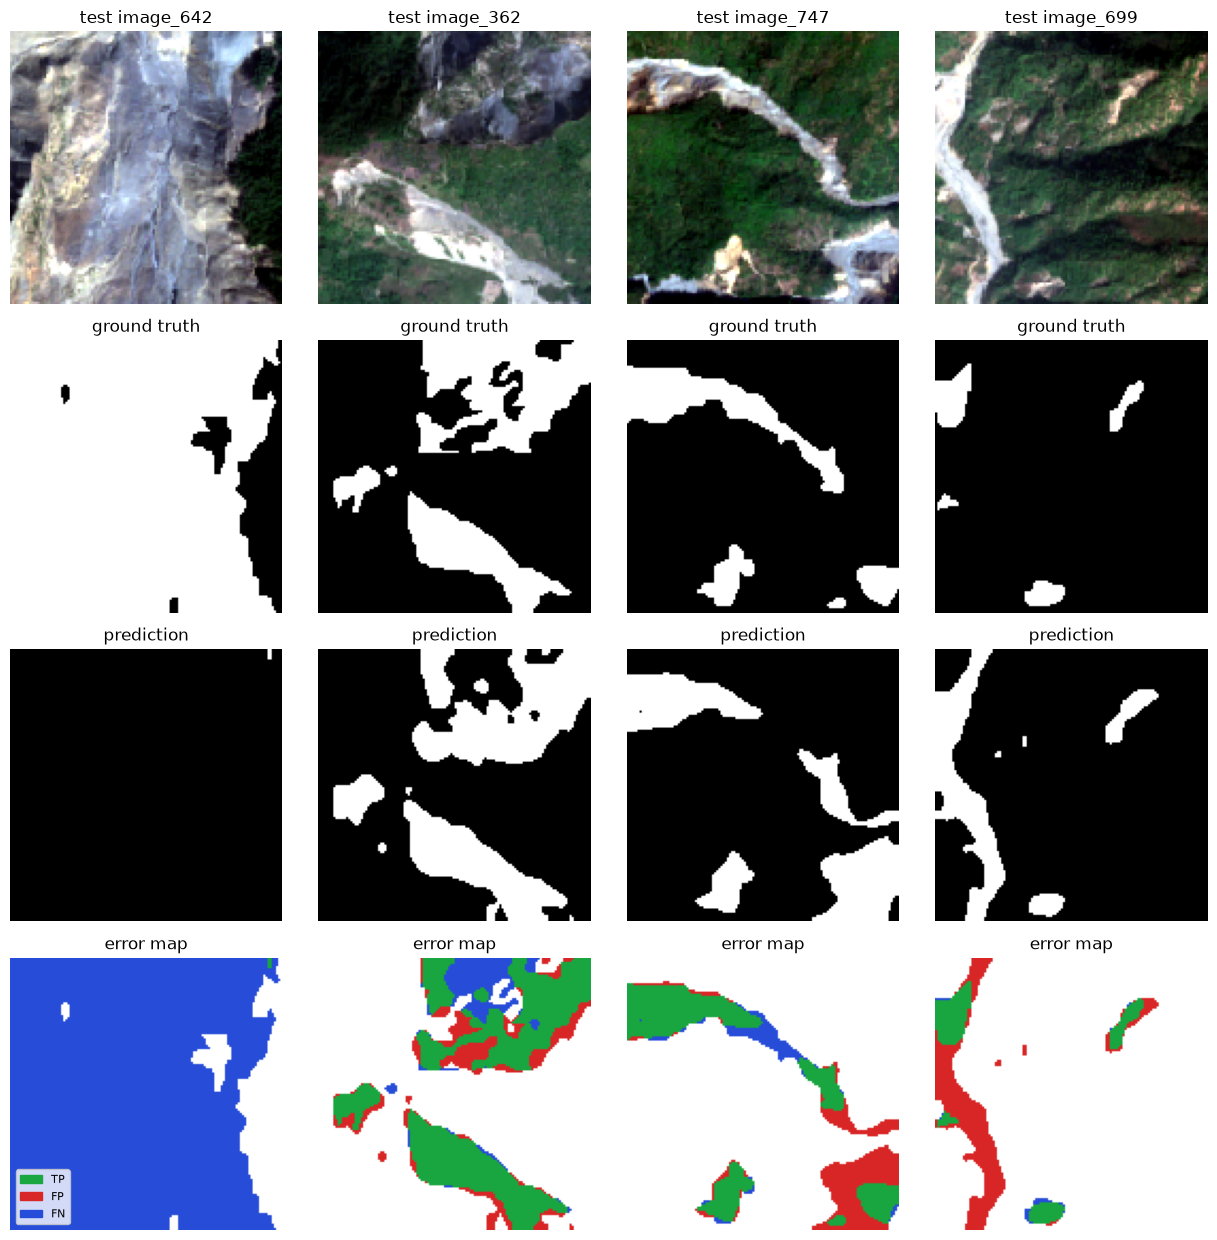

In [9]:
def rgb_composite(img14: np.ndarray) -> np.ndarray:
    """True-color (B4/B3/B2) composite, 2–98 percentile stretch for display."""
    rgb = img14[:, :, [3, 2, 1]]
    lo, hi = np.percentile(rgb, (2, 98), axis=(0, 1))
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

def error_map(gt: np.ndarray, pred: np.ndarray) -> np.ndarray:
    """White=TN, green=TP, red=FP, blue=FN."""
    out = np.ones((*gt.shape, 3))
    out[(gt == 1) & (pred == 1)] = [0.10, 0.65, 0.25]   # TP
    out[(gt == 0) & (pred == 1)] = [0.85, 0.15, 0.15]   # FP
    out[(gt == 1) & (pred == 0)] = [0.15, 0.30, 0.85]   # FN
    return out

# test patches sorted by landslide coverage -> pick 4 interesting ones
gt_cover = gts.float().mean(dim=(1, 2)).numpy()
test_files = datamodule.test_dataset.image_files           # sorted like preds/gts
show = np.argsort(gt_cover)[::-1][[0, 5, 20, 80]]

fig, axes = plt.subplots(4, 4, figsize=(12.5, 12.5))
for col, i in enumerate(show):
    idx = int(test_files[i].stem.split("_")[1])            # file number of this sample
    img14, _ = load_sample("test", idx)
    gt_i, pred_i = gts[i].numpy(), preds[i].numpy()
    axes[0, col].imshow(rgb_composite(img14)); axes[0, col].set_title(f"test image_{idx}")
    axes[1, col].imshow(gt_i, cmap="gray");    axes[1, col].set_title("ground truth")
    axes[2, col].imshow(pred_i, cmap="gray");  axes[2, col].set_title("prediction")
    axes[3, col].imshow(error_map(gt_i, pred_i)); axes[3, col].set_title("error map")
for ax in axes.ravel():
    ax.axis("off")
axes[3, 0].legend(handles=[
    mpatches.Patch(color=(0.10, 0.65, 0.25), label="TP"),
    mpatches.Patch(color=(0.85, 0.15, 0.15), label="FP"),
    mpatches.Patch(color=(0.15, 0.30, 0.85), label="FN"),
], loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "test_predictions_errormaps.png", dpi=120)
plt.show()


---
## Section 6. Quantitative evaluation on the test split *(≈10 min)*

### 🎯 Objective
Put trustworthy numbers on the model — and read them the way a reviewer would.

We compute everything from the **pixel-level confusion matrix** over all 800 test patches (≈13.1M pixels), focusing on the **landslide class**:

- **Precision** = TP / (TP + FP) — *when the model cries "landslide", how often is it right?*
- **Recall** = TP / (TP + FN) — *how much of the true landslide area does it find?*
- **F1** (Dice) — harmonic mean of the two;
- **IoU** (Jaccard) — overlap / union, the segmentation community's favorite; always ≤ F1.

Under heavy class imbalance, overall pixel accuracy is nearly meaningless (predicting "no landslide" everywhere already scores ~98%). The per-class numbers below are the honest ones.


                        value
metric                       
precision (landslide)  0.5698
recall (landslide)     0.6480
F1 (landslide)         0.6064
IoU (landslide)        0.4351
IoU (background)       0.9839
mean IoU               0.7095
pixel accuracy         0.9841


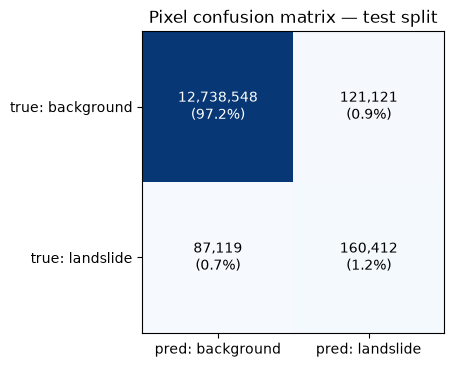

In [10]:
from torchmetrics.classification import BinaryConfusionMatrix

cm = BinaryConfusionMatrix()(preds.flatten(), gts.flatten()).numpy()
(tn, fp), (fn, tp) = cm

precision = tp / (tp + fp)
recall    = tp / (tp + fn)
f1        = 2 * precision * recall / (precision + recall)
iou_ls    = tp / (tp + fp + fn)                 # landslide IoU
iou_bg    = tn / (tn + fn + fp)                 # background IoU
accuracy  = (tp + tn) / cm.sum()

metrics = pd.DataFrame({
    "metric": ["precision (landslide)", "recall (landslide)", "F1 (landslide)",
               "IoU (landslide)", "IoU (background)", "mean IoU", "pixel accuracy"],
    "value": [precision, recall, f1, iou_ls, iou_bg, (iou_ls + iou_bg) / 2, accuracy],
}).set_index("metric").round(4)
metrics.to_csv(OUT_DIR / "test_metrics.csv")
print(metrics)

# confusion matrix as a normalized heatmap
fig, ax = plt.subplots(figsize=(4.4, 3.8))
cm_norm = cm / cm.sum()
im_ = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for r in range(2):
    for c in range(2):
        ax.text(c, r, f"{cm[r, c]:,}\n({cm_norm[r, c]:.1%})",
                ha="center", va="center",
                color="white" if cm_norm[r, c] > 0.5 else "black", fontsize=10)
ax.set_xticks([0, 1], ["pred: background", "pred: landslide"])
ax.set_yticks([0, 1], ["true: background", "true: landslide"])
ax.set_title("Pixel confusion matrix — test split")
fig.tight_layout()
fig.savefig(OUT_DIR / "confusion_matrix.png", dpi=120)
plt.show()


As a cross-check, `trainer.test(...)` runs TerraTorch's own metric suite (the same metrics that were logged during training) on the test split — the numbers should agree with our manual computation above up to rounding. In your own work, computing a metric **two independent ways once** is cheap insurance against silent evaluation bugs.


In [11]:
trainer = pl.Trainer(accelerator="auto", devices=1, logger=False, enable_progress_bar=False)
test_results = trainer.test(task, datamodule=datamodule, verbose=False)
pd.DataFrame([
    {"metric": k.replace("test/", ""), "value": round(v, 4)}
    for k, v in test_results[0].items()
]).set_index("metric")


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


/home/exouser/miniconda3/envs/landslide/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


,value
metric,
loss,0.2368
Accuracy,0.8193
Boundary_mIoU,0.3282
Class_Accuracy_0,0.9906
Class_Accuracy_1,0.6480
F1_Score,0.7991
IoU_0,0.9839
IoU_1,0.4351
Pixel_Accuracy,0.9841


---
## Section 7. Thresholding & post-processing *(≈10 min)*

### 🎯 Objective
See that `argmax` is just one point on a dial — and learn two cheap levers that change the precision/recall balance *without retraining*.

### 7a. Probability thresholding

`argmax` on two classes is the same as thresholding the landslide probability at **0.5**. But many applications are asymmetric: a rapid-response mapping team may prefer **recall** (missing a landslide is worse than a false alarm), while an insurance model may prefer **precision**. Sweeping the threshold traces that trade-off. We tune on ~13M test pixels here for speed of presentation; in real work, tune the threshold on the **validation** split and only then report test numbers — tuning on test is a classic form of leakage.


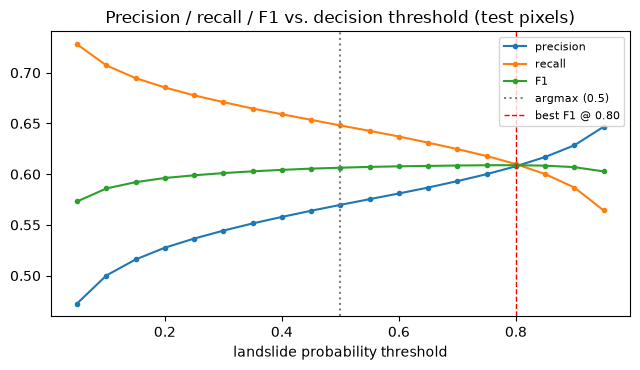

{'threshold': 0.8, 'precision': 0.608, 'recall': 0.61, 'F1': 0.609}


In [12]:
thresholds = np.linspace(0.05, 0.95, 19)
probs_flat = probs.flatten().numpy()
gts_flat = gts.flatten().numpy().astype(bool)

rows = []
for t in thresholds:
    hard = probs_flat >= t
    tp_ = (hard & gts_flat).sum(); fp_ = (hard & ~gts_flat).sum(); fn_ = (~hard & gts_flat).sum()
    p_ = tp_ / max(tp_ + fp_, 1); r_ = tp_ / max(tp_ + fn_, 1)
    rows.append({"threshold": t, "precision": p_, "recall": r_,
                 "F1": 2 * p_ * r_ / max(p_ + r_, 1e-9)})
sweep = pd.DataFrame(rows)
best = sweep.loc[sweep["F1"].idxmax()]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for colname in ["precision", "recall", "F1"]:
    ax.plot(sweep["threshold"], sweep[colname], label=colname, marker=".")
ax.axvline(0.5, color="gray", ls=":", label="argmax (0.5)")
ax.axvline(best["threshold"], color="red", ls="--", lw=1,
           label=f"best F1 @ {best['threshold']:.2f}")
ax.set_xlabel("landslide probability threshold"); ax.legend(fontsize=8)
ax.set_title("Precision / recall / F1 vs. decision threshold (test pixels)")
fig.tight_layout()
fig.savefig(OUT_DIR / "threshold_sweep.png", dpi=120)
plt.show()
print(best.round(3).to_dict())


### 7b. Morphological post-processing

Pixel-wise models produce **speckle**: isolated false-positive pixels and ragged edges. A *morphological opening* (erosion followed by dilation) removes connected components smaller than the structuring element — a one-liner that often makes maps far more presentable, at the cost of erasing genuinely tiny landslides. Below: one test patch, before and after.


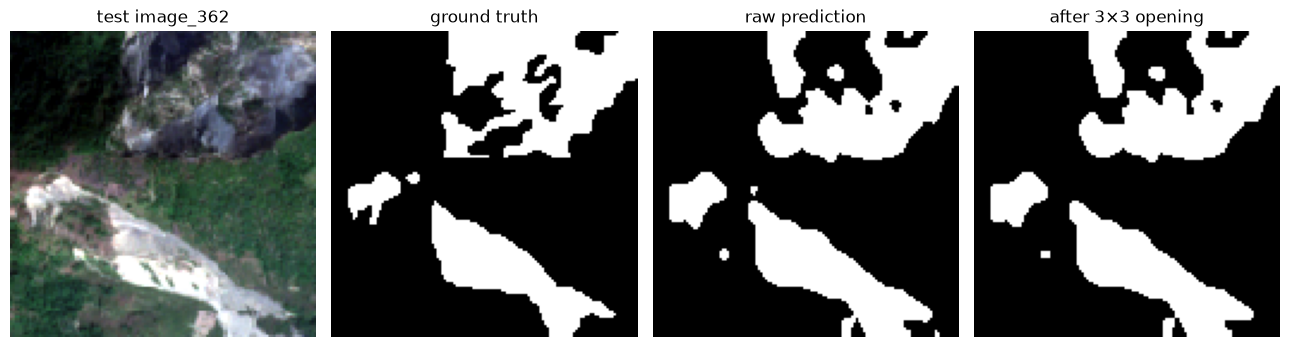

raw positive pixels: 4859  |  after opening: 4820


In [13]:
from scipy import ndimage

i = int(np.argsort(gt_cover)[::-1][5])                 # a patch with a sizeable landslide
idx = int(test_files[i].stem.split("_")[1])
img14, _ = load_sample("test", idx)
raw = (probs[i].numpy() >= 0.5)
cleaned = ndimage.binary_opening(raw, structure=np.ones((3, 3)))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
axes[0].imshow(rgb_composite(img14));        axes[0].set_title(f"test image_{idx}")
axes[1].imshow(gts[i].numpy(), cmap="gray"); axes[1].set_title("ground truth")
axes[2].imshow(raw, cmap="gray");            axes[2].set_title("raw prediction")
axes[3].imshow(cleaned, cmap="gray");        axes[3].set_title("after 3×3 opening")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT_DIR / "postprocessing_example.png", dpi=120)
plt.show()
print(f"raw positive pixels: {raw.sum()}  |  after opening: {cleaned.sum()}")


---
## Section 8. Limitations & applying this to your own data *(≈5 min)*

### 🎯 Objective
Leave with a realistic sense of what this model can and cannot do.

### Honest limitations

1. **Patch-sized context.** The model sees 128×128 windows (~1.3 km). Landslides interacting with larger terrain structures, or runouts crossing patch borders, are judged from partial evidence. For wall-to-wall mapping you would tile a scene with overlap and blend the seams.
2. **No topography.** We dropped slope and DEM to match Prithvi's pretraining bands — yet slope is among the strongest landslide predictors. Extending the input embedding to extra channels (TerraTorch supports this) is the obvious next experiment.
3. **Single-date imagery.** Fresh landslides are easiest to see in *change* (before vs. after an event). Prithvi-EO-2.0 natively supports multi-temporal stacks — a natural extension this workshop skipped for time.
4. **Benchmark ≠ the world.** Landslide4Sense's patches were curated around known events. Expect lower precision on wall-to-wall imagery full of look-alikes (quarries, riverbanks, burn scars, fresh clear-cuts), and treat the test metrics here as an optimistic bound.
5. **Labels are imperfect.** Landslide inventories miss events and disagree on boundaries; part of the "error" you saw in Section 5 is label noise, not model failure.

### Applying this to your region — a checklist

1. **Imagery:** Sentinel-2 L2A (or HLS) for your area and dates; select the 6 bands in Section 3's order and scale/standardize consistently — if you train on your own data, compute your own band statistics.
2. **Labels:** a landslide inventory (polygons) rasterized to your grid. Even a few hundred 128×128 patches can be enough to fine-tune — that is the point of foundation models.
3. **Splits:** split **geographically** (by region/event), never randomly by patch — random splits leak spatially correlated pixels and inflate your metrics.
4. **Fine-tune** with the Part 1 recipe (same config, your datamodule). Start from the Landslide4Sense checkpoint rather than raw Prithvi if your task is similar.
5. **Validate visually** with Section 5's error maps before trusting any number — and report precision *and* recall, not just one.
